In [1]:
import tensorflow as tf
import os
import cv2
import imghdr
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# Avoid OOM errors by setting GPU Memory Consumption Growth
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus: 
    tf.config.experimental.set_memory_growth(gpu, True)

In [3]:
data_dir = 'data'

In [4]:
image_exts = ['jpeg','jpg', 'bmp', 'png']

In [5]:
for image_class in os.listdir(data_dir): 
    for image in os.listdir(os.path.join(data_dir, image_class)):
        image_path = os.path.join(data_dir, image_class, image)
        try: 
            img = cv2.imread(image_path)
            tip = imghdr.what(image_path)
            if tip not in image_exts: 
                print('Image not in ext list {}'.format(image_path))
                os.remove(image_path)
        except Exception as e: 
            print('Issue with image {}'.format(image_path))
            # os.remove(image_path)

In [6]:
data = tf.keras.utils.image_dataset_from_directory('data')

Found 56 files belonging to 2 classes.


In [7]:
data_iterator = data.as_numpy_iterator()

In [8]:
batch = data_iterator.next()

In [9]:
batch[0].shape

(32, 256, 256, 3)

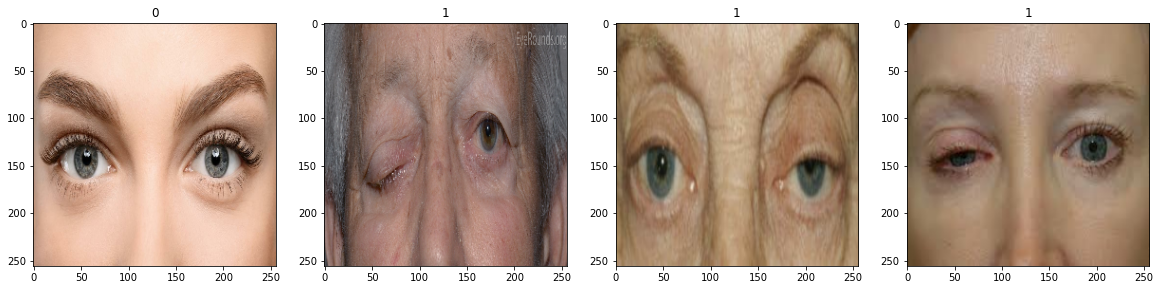

In [10]:
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    ax[idx].title.set_text(batch[1][idx])

In [11]:
data = data.map(lambda x,y: (x/255, y))

In [12]:
data.as_numpy_iterator().next()

(array([[[[0.03529412, 0.03529412, 0.03529412],
          [0.03912377, 0.03912377, 0.03912377],
          [0.03167892, 0.03167892, 0.03167892],
          ...,
          [0.03121936, 0.03121936, 0.03121936],
          [0.02735907, 0.02735907, 0.02735907],
          [0.02352941, 0.02352941, 0.02352941]],
 
         [[0.0407935 , 0.0407935 , 0.0407935 ],
          [0.04193791, 0.04193791, 0.04193791],
          [0.03178633, 0.03178633, 0.03178633],
          ...,
          [0.03121936, 0.03121936, 0.03121936],
          [0.02735907, 0.02735907, 0.02735907],
          [0.02352941, 0.02352941, 0.02352941]],
 
         [[0.0451057 , 0.0451057 , 0.0451057 ],
          [0.04318339, 0.04318339, 0.04318339],
          [0.03183211, 0.03183211, 0.03183211],
          ...,
          [0.03121936, 0.03121936, 0.03121936],
          [0.02735907, 0.02735907, 0.02735907],
          [0.02352941, 0.02352941, 0.02352941]],
 
         ...,
 
         [[0.10783548, 0.11175705, 0.09214921],
          [0.10592

In [13]:
len(data)

2

In [14]:
train_size = 1
val_size = 1
test_size = 0

In [15]:
train = data.take(train_size)
val = data.skip(train_size).take(val_size)
test = data.skip(train_size+val_size).take(test_size)

In [16]:
train

<TakeDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout

In [18]:
model = Sequential()

In [19]:
model.add(Conv2D(16, (3,3), 1, activation='relu', input_shape=(256,256,3)))
model.add(MaxPooling2D())
model.add(Conv2D(32, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())
model.add(Conv2D(16, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [20]:
model.compile('adam', loss=tf.losses.BinaryCrossentropy(), metrics=['accuracy'])

In [21]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 254, 254, 16)      448       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 127, 127, 16)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 125, 125, 32)      4640      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 62, 62, 32)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 60, 60, 16)        4624      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 30, 30, 16)       0

In [22]:
logdir='logs'

In [23]:
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=logdir)

In [24]:
hist = model.fit(train, epochs=40, validation_data=val, callbacks=[tensorboard_callback])

Epoch 1/40
1/1 [==============================] - 1s 1s/step - loss: 0.6820 - accuracy: 0.6875 - val_loss: 2.1939 - val_accuracy: 0.5833
Epoch 2/40
1/1 [==============================] - 1s 862ms/step - loss: 2.0951 - accuracy: 0.5938 - val_loss: 0.6551 - val_accuracy: 0.8750
Epoch 3/40
1/1 [==============================] - 1s 879ms/step - loss: 0.6528 - accuracy: 0.7500 - val_loss: 0.7411 - val_accuracy: 0.5000
Epoch 4/40
1/1 [==============================] - 1s 849ms/step - loss: 0.8621 - accuracy: 0.3750 - val_loss: 0.7755 - val_accuracy: 0.3333
Epoch 5/40
1/1 [==============================] - 1s 918ms/step - loss: 0.7612 - accuracy: 0.3438 - val_loss: 0.6727 - val_accuracy: 0.4583
Epoch 6/40
1/1 [==============================] - 1s 850ms/step - loss: 0.6715 - accuracy: 0.4375 - val_loss: 0.6446 - val_accuracy: 0.6250
Epoch 7/40
1/1 [==============================] - 1s 829ms/step - loss: 0.6620 - accuracy: 0.5625 - val_loss: 0.6189 - val_accuracy: 0.7500
Epoch 8/40
1/1 [=======

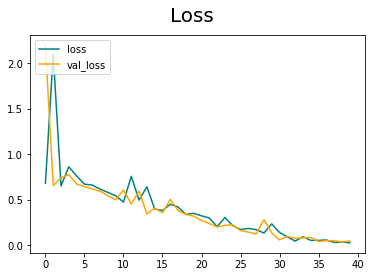

In [25]:
fig = plt.figure()
plt.plot(hist.history['loss'], color='teal', label='loss')
plt.plot(hist.history['val_loss'], color='orange', label='val_loss')
fig.suptitle('Loss', fontsize=20)
plt.legend(loc="upper left")
plt.show()

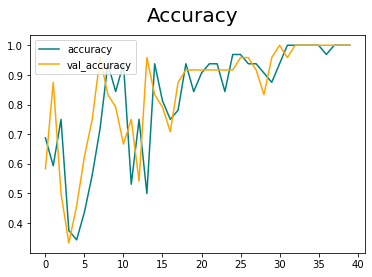

In [26]:
fig = plt.figure()
plt.plot(hist.history['accuracy'], color='teal', label='accuracy')
plt.plot(hist.history['val_accuracy'], color='orange', label='val_accuracy')
fig.suptitle('Accuracy', fontsize=20)
plt.legend(loc="upper left")
plt.show()

In [27]:
from tensorflow.keras.metrics import Precision, Recall, BinaryAccuracy

In [28]:
pre = Precision()
re = Recall()
acc = BinaryAccuracy()

In [29]:
for batch in test.as_numpy_iterator(): 
    X, y = batch
    yhat = model.predict(X)
    pre.update_state(y, yhat)
    re.update_state(y, yhat)
    acc.update_state(y, yhat)

In [30]:
print(pre.result(), re.result(), acc.result())

tf.Tensor(0.0, shape=(), dtype=float32) tf.Tensor(0.0, shape=(), dtype=float32) tf.Tensor(0.0, shape=(), dtype=float32)


In [31]:
import cv2

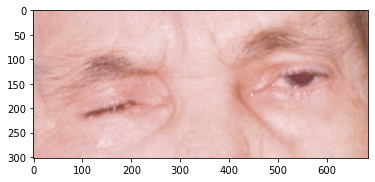

In [36]:
img = cv2.imread('ptosis4test.jpg')
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

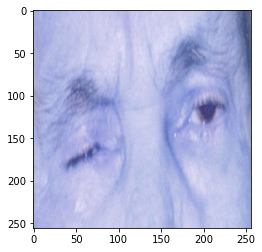

In [37]:
resize = tf.image.resize(img, (256,256))
plt.imshow(resize.numpy().astype(int))
plt.show()

In [38]:
yhat = model.predict(np.expand_dims(resize/255, 0))

1/1 [==============================] - 0s 78ms/step


In [39]:
if yhat > 0.7: 
    print(f'Eye with Ptosis')
else:
    print(f'No Ptosis')

No Ptosis


In [40]:
yhat

array([[0.00902861]], dtype=float32)